In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("ai4i2020.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nStatistical summary:")
display(df.describe(include="all").T)

Column names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Data types:
UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UDI,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
Product ID,10000,10000,M14860,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Machine failure,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0
TWF,10000.0,NaN,NaN,NaN,0.0046,0.067671,0.0,0.0,0.0,0.0,1.0


In [4]:
print("Missing values:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Total missing values: 0

Duplicate rows: 0


In [5]:
df = df.drop_duplicates().copy()

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

df[numeric_cols] = df[numeric_cols].replace(
    [np.inf, -np.inf], np.nan
)

print("Dataset shape after duplicate removal:", df.shape)

print("\nMissing values after validation:")
print(df.isnull().sum())

Dataset shape after duplicate removal: (10000, 14)

Missing values after validation:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


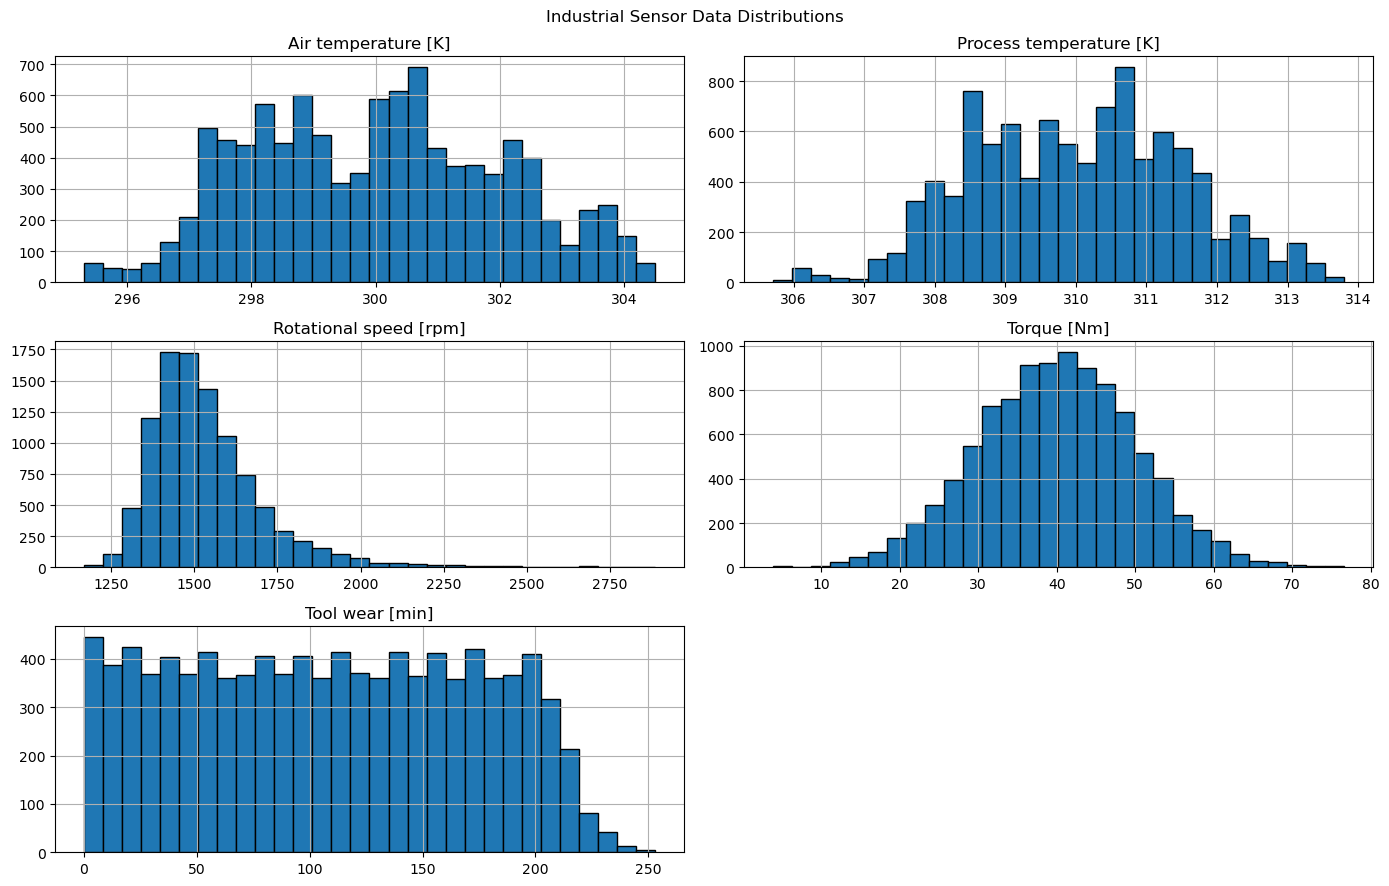

In [6]:
sensor_cols = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df[sensor_cols].hist(
    figsize=(14, 9),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Industrial Sensor Data Distributions")
plt.tight_layout()
plt.show()

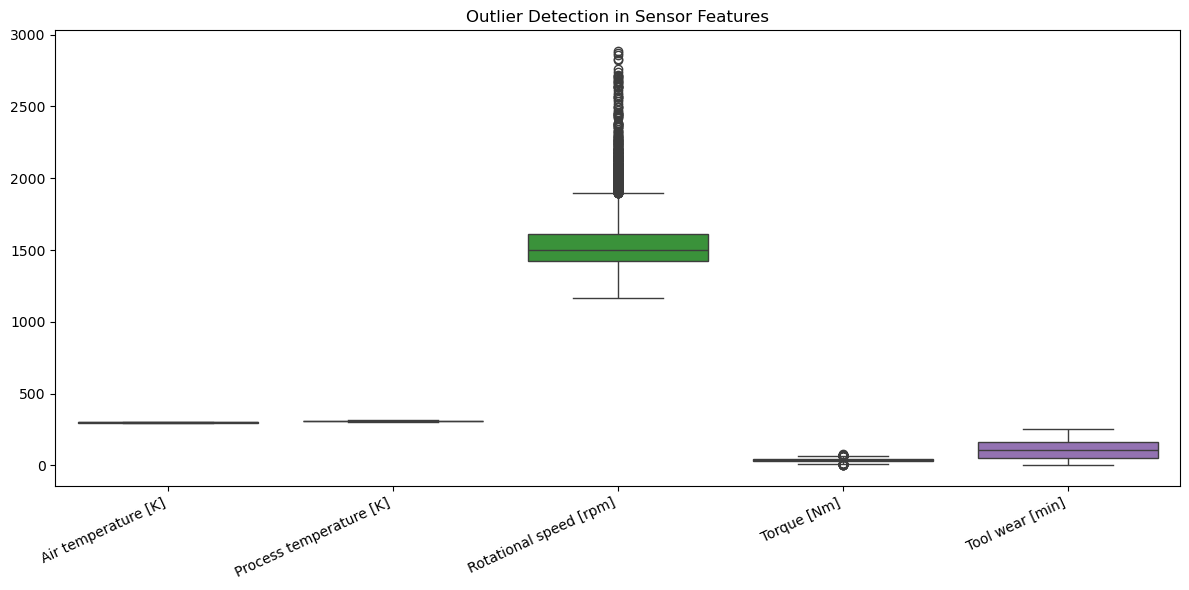

Air temperature [K]: 0 potential outliers
Process temperature [K]: 0 potential outliers
Rotational speed [rpm]: 418 potential outliers
Torque [Nm]: 69 potential outliers
Tool wear [min]: 0 potential outliers


In [7]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df[sensor_cols])

plt.title("Outlier Detection in Sensor Features")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

for col in sensor_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    print(f"{col}: {count} potential outliers")

Failure counts:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure percentages:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


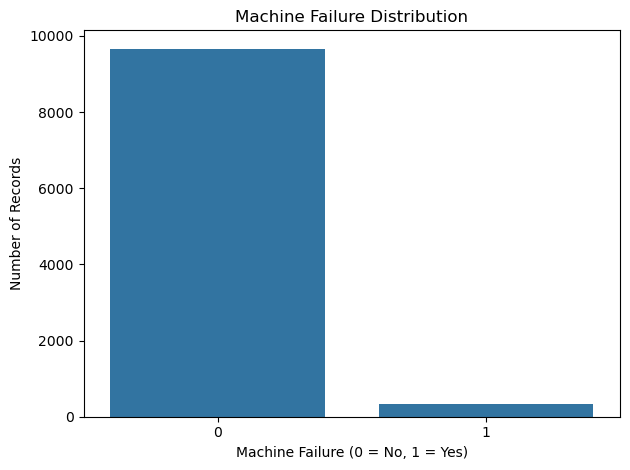

In [8]:
target = "Machine failure"

print("Failure counts:")
print(df[target].value_counts())

print("\nFailure percentages:")
print((df[target].value_counts(normalize=True) * 100).round(2))

sns.countplot(data=df, x=target)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

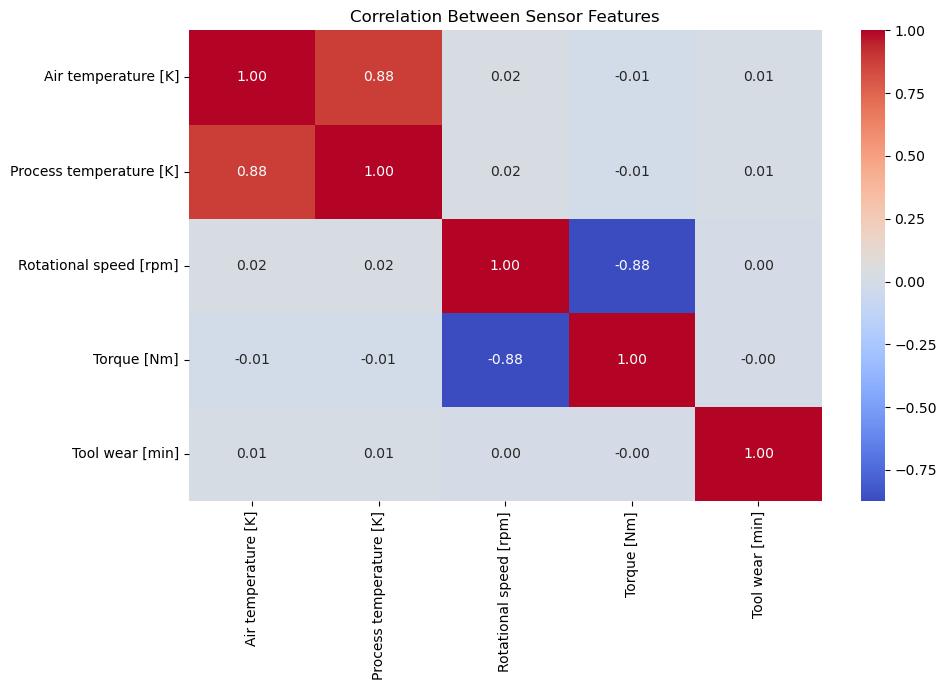

In [9]:
plt.figure(figsize=(10, 7))

correlation = df[sensor_cols].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Sensor Features")
plt.tight_layout()
plt.show()

In [10]:
target = "Machine failure"

drop_cols = [
    "UDI",
    "Product ID",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

X = df.drop(columns=[target] + drop_cols)
y = df[target]

print("Selected input features:")
print(X.columns.tolist())

print("\nFeature matrix shape:", X.shape)
print("Target shape:", y.shape)

Selected input features:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

Feature matrix shape: (10000, 6)
Target shape: (10000,)


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (8000, 6)
Testing features: (2000, 6)

Training target distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing target distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (8000, 8)
Processed testing shape: (2000, 8)


In [13]:
feature_names = preprocessor.get_feature_names_out()

if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()

if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names
)

print("Final training dataset:")
display(X_train_processed.head())

print("\nFinal testing dataset:")
display(X_test_processed.head())

print("\nTraining missing values:", X_train_processed.isnull().sum().sum())
print("Testing missing values:", X_test_processed.isnull().sum().sum())

print("\nPreprocessing completed successfully!")

Final training dataset:


,numeric__Air temperature [K],numeric__Process temperature [K],numeric__Rotational speed [rpm],numeric__Torque [Nm],numeric__Tool wear [min],categorical__Type_H,categorical__Type_L,categorical__Type_M
0,0.998914,0.604282,-0.460607,0.718305,-0.843997,0.0,0.0,1.0
1,-1.505194,-1.153260,-0.775574,0.638456,0.382263,0.0,0.0,1.0
2,0.498092,1.077466,-1.007654,0.558607,0.460870,0.0,0.0,1.0
3,-0.553633,-0.139294,-0.709265,1.626586,-0.372359,0.0,1.0,0.0
4,-1.455112,-1.018064,1.070019,-1.128202,-0.906882,0.0,1.0,0.0



Final testing dataset:


,numeric__Air temperature [K],numeric__Process temperature [K],numeric__Rotational speed [rpm],numeric__Torque [Nm],numeric__Tool wear [min],categorical__Type_H,categorical__Type_L,categorical__Type_M
0,0.247681,-0.139294,-1.073963,2.265378,0.712410,0.0,1.0,0.0
1,1.850310,1.618248,-0.145641,0.009646,0.429427,0.0,1.0,0.0
2,1.249324,0.942270,0.108543,-0.239882,1.592802,0.0,1.0,0.0
3,-2.206344,-2.505215,-0.167744,-0.419543,-0.749670,1.0,0.0,0.0
4,0.247681,-0.004098,-1.002129,2.035812,-0.089376,1.0,0.0,0.0



Training missing values: 0
Testing missing values: 0

Preprocessing completed successfully!
